In [1]:
import sys
import chemprop
import torch
import pandas as pd

print("Python:", sys.version)
print("Chemprop:", chemprop.__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

Python: 3.11.18 (main, Oct 26 2026, 11:35:17) [GCC 15.3.0]
Chemprop: 2.3.1
PyTorch: 2.15.0+cu132
CUDA: True


In [2]:
import os

base_dir = "/data/Zira/Chemprop_Kd_Mann"

print("Folder tersedia:", os.path.exists(base_dir))

if os.path.exists(base_dir):
    print(os.listdir(base_dir))

Folder tersedia: True
['Untitled.ipynb', 'USP5_mann_53_Kd.csv', 'runs', 'Untitled2.ipynb', '1_53.ipynb', 'USP5_Mann_baseline', 'instalasi_cehmprop_workspace.ipynb', 'USP5_mann_53_Kd_chemprop.csv', 'USP5_clean.csv', 'Untitled1.ipynb', '.ipynb_checkpoints']


In [4]:
import pandas as pd

file_path = "/data/Zira/Chemprop_Kd_Mann/USP5_mann_53_Kd.csv"

df = pd.read_csv(file_path)

print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

display(df.head())

Ukuran dataset: (53, 3)

Nama kolom:
['Molecule ChEMBL ID', 'Smiles', 'pKd']


,Molecule ChEMBL ID,Smiles,pKd
0,CHEMBL5285743,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057
1,CHEMBL5290717,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.346787
2,CHEMBL5285627,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.638272
3,CHEMBL5274675,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.102373
4,CHEMBL5276984,Cn1cc(S(=O)(=O)N2CCC(c3ccccc3)CC2)cc1C(=O)NCC(...,3.823909


In [5]:
from rdkit import Chem
import pandas as pd
import numpy as np

# Salin dataset
df_check = df.copy()

# Periksa SMILES
df_check["Mol"] = df_check["Smiles"].apply(
    lambda x: Chem.MolFromSmiles(str(x))
)

# Periksa validitas
df_check["Valid_SMILES"] = df_check["Mol"].notna()

print("Total senyawa:", len(df_check))
print("SMILES valid:", df_check["Valid_SMILES"].sum())
print("SMILES tidak valid:", (~df_check["Valid_SMILES"]).sum())

# Periksa missing value
print("\nMissing value:")
print(df_check[["Smiles", "pKd"]].isnull().sum())

# Periksa duplikat
print("\nDuplikat SMILES:", df_check["Smiles"].duplicated().sum())

# Statistik pKd
print("\nStatistik pKd:")
print(df_check["pKd"].describe())

Total senyawa: 53
SMILES valid: 53
SMILES tidak valid: 0

Missing value:
Smiles    0
pKd       0
dtype: int64

Duplikat SMILES: 0

Statistik pKd:
count    53.000000
mean      4.394154
std       0.464943
min       3.568636
25%       4.060481
50%       4.376751
75%       4.677781
max       5.552842
Name: pKd, dtype: float64


In [11]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold

# Membuat kelompok berdasarkan distribusi pKd
df = df.reset_index(drop=True)
df["pKd_group"] = pd.qcut(
    df["pKd"],
    q=5,
    labels=False,
    duplicates="drop"
)

# Stratified 10-fold
skf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

df["Fold"] = 0

for fold, (_, test_idx) in enumerate(
    skf.split(df, df["pKd_group"]),
    start=1
):
    df.loc[test_idx, "Fold"] = fold

# Periksa distribusi
print(df.groupby("Fold").agg(
    jumlah_senyawa=("Smiles", "count"),
    rata_rata_pKd=("pKd", "mean"),
    minimum_pKd=("pKd", "min"),
    maksimum_pKd=("pKd", "max")
))

# Simpan pembagian
output_path = (
    "/data/Zira/Chemprop_Kd_Mann/1_53/"
    "USP5_mann_53_Kd_10fold_seed42.csv"
)

df.drop(columns=["pKd_group"]).to_csv(
    output_path,
    index=False
)

print("\nFile berhasil disimpan:", output_path)

      jumlah_senyawa  rata_rata_pKd  minimum_pKd  maksimum_pKd
Fold                                                          
1                  6       4.280178     3.823909      4.886057
2                  6       4.265435     3.823909      4.744727
3                  6       4.481446     3.769551      5.096910
4                  5       4.374631     3.823909      5.045757
5                  5       4.441331     3.886057      5.045757
6                  5       4.354984     3.657577      4.795880
7                  5       4.378461     3.568636      5.468521
8                  5       4.497176     4.026872      5.154902
9                  5       4.467817     3.677781      5.552842
10                 5       4.431161     3.958607      5.154902

File berhasil disimpan: /data/Zira/Chemprop_Kd_Mann/1_53/USP5_mann_53_Kd_10fold_seed42.csv


In [13]:
import pandas as pd
import numpy as np
import json
import os

# Membaca dataset dengan nomor fold
split_path = (
    "/data/Zira/Chemprop_Kd_Mann/1_53/"
    "USP5_mann_53_Kd_10fold_seed42.csv"
)

df_split = pd.read_csv(split_path)

splits = []

# Membuat 10 kombinasi training dan testing
for fold in range(1, 11):

    test_idx = np.where(
        df_split["Fold"].values == fold
    )[0].tolist()

    train_idx = np.where(
        df_split["Fold"].values != fold
    )[0].tolist()

    splits.append({
        "train": train_idx,
        "test": test_idx
    })

# Menyimpan JSON
json_path = (
    "/data/Zira/Chemprop_Kd_Mann/1_53/"
    "USP5_mann_53_Kd_splits.json"
)

with open(json_path, "w") as f:
    json.dump(splits, f, indent=4)

print("Splits berhasil dibuat!")
print("Lokasi:", json_path)

# Pemeriksaan
for i, split in enumerate(splits, start=1):
    print(
        f"Fold {i}: "
        f"Train = {len(split['train'])}, "
        f"Test = {len(split['test'])}"
    )


Splits berhasil dibuat!
Lokasi: /data/Zira/Chemprop_Kd_Mann/1_53/USP5_mann_53_Kd_splits.json
Fold 1: Train = 47, Test = 6
Fold 2: Train = 47, Test = 6
Fold 3: Train = 47, Test = 6
Fold 4: Train = 48, Test = 5
Fold 5: Train = 48, Test = 5
Fold 6: Train = 48, Test = 5
Fold 7: Train = 48, Test = 5
Fold 8: Train = 48, Test = 5
Fold 9: Train = 48, Test = 5
Fold 10: Train = 48, Test = 5


In [14]:
print(os.path.exists(json_path))

True


In [15]:
import json

with open(json_path, "r") as f:
    splits_check = json.load(f)

print("Jumlah fold:", len(splits_check))
print("Contoh fold pertama:")
print(splits_check[0])

assert len(splits_check) == 10

for i, split in enumerate(splits_check, 1):
    assert len(split["train"]) + len(split["test"]) == 53
    assert set(split["train"]).isdisjoint(split["test"])
    assert len(set(split["train"] + split["test"])) == 53

print("\nSemua pembagian fold valid.")

Jumlah fold: 10
Contoh fold pertama:
{'train': [0, 2, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 20, 21, 22, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52], 'test': [1, 4, 19, 23, 24, 35]}

Semua pembagian fold valid.


In [16]:
import os

data_path = (
    "/data/Zira/Chemprop_Kd_Mann/1_53/"
    "USP5_mann_53_Kd_10fold_seed42.csv"
)

output_dir = (
    "/data/Zira/Chemprop_Kd_Mann/1_53/"
    "DMPNN_10Fold_Baseline"
)

os.makedirs(output_dir, exist_ok=True)

In [17]:
import subprocess

test_splits = [splits_check[0]]

test_json = os.path.join(output_dir, "test_fold1.json")

with open(test_json, "w") as f:
    json.dump(test_splits, f, indent=4)

cmd = [
    "chemprop", "train",
    "--data-path", data_path,
    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",
    "--task-type", "regression",
    "--splits-file", test_json,
    "--output-dir", os.path.join(output_dir, "Fold1"),
    "--message-hidden-dim", "300",
    "--depth", "3",
    "--dropout", "0.1",
    "--batch-size", "16",
    "--epochs", "100",
    "--pytorch-seed", "42",
    "--accelerator", "gpu",
    "--devices", "1",
    "--metrics", "rmse", "mae", "r2"
]

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-5000:])
print(result.stderr[-3000:])

FileNotFoundError: [Errno 2] No such file or directory: 'chemprop'

In [18]:
#####################################
# checking location of chemprop     #
#####################################
import sys
import os
import shutil
import importlib.metadata as metadata

print("Python executable:")
print(sys.executable)

print("\nEnvironment:")
print(sys.prefix)

print("\nChemprop executable:")
print(shutil.which("chemprop"))

print("\nPackage location:")
import chemprop
print(chemprop.__file__)

print("\nInstalled CLI entry point:")
for ep in metadata.entry_points(group="console_scripts"):
    if "chemprop" in ep.name.lower():
        print(ep.name, "=", ep.value)

Python executable:
/workspace/miniforge3/envs/chemprop/bin/python

Environment:
/workspace/miniforge3/envs/chemprop

Chemprop executable:
None

Package location:
/workspace/miniforge3/envs/chemprop/lib/python3.11/site-packages/chemprop/__init__.py

Installed CLI entry point:
chemprop = chemprop.cli.main:main


In [19]:
chemprop_path = os.path.join(sys.prefix, "bin", "chemprop")

print("Lokasi:", chemprop_path)
print("File tersedia:", os.path.exists(chemprop_path))

Lokasi: /workspace/miniforge3/envs/chemprop/bin/chemprop
File tersedia: True


In [20]:
import subprocess
import sys

cmd = [
    sys.executable,
    "-c",
    "from chemprop.cli import main; main()",
    "--version"
]

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("Output:", result.stdout)
print("Error:", result.stderr)

Return code: 1
Output: 
Error: Traceback (most recent call last):
  File "<string>", line 1, in <module>
TypeError: 'module' object is not callable



In [21]:
import subprocess
import sys

cmd = [
    sys.executable,
    "-c",
    "from importlib.metadata import entry_points; entry_points(group='console_scripts', name='chemprop')[0].load()()",
    "--version"
]

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("Output:", result.stdout)
print("Error:", result.stderr)

Return code: 0
Output: chemprop 2.3.1

Error: <string>:1: DeprecationWarning: Accessing entry points by index is deprecated. Cast to tuple if needed.



In [22]:
cmd = [
    sys.executable,
    "-c",
    "from importlib.metadata import entry_points; entry_points(group='console_scripts', name='chemprop')[0].load()()",
    "train",
    "--help"
]

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print(result.stdout[:5000])
print(result.stderr[:2000])

usage: -c train [-h] [--logfile [LOGFILE]] [-v] [-q]
                [-s SMILES_COLUMNS [SMILES_COLUMNS ...]]
                [-r REACTION_COLUMNS [REACTION_COLUMNS ...]] [--no-header-row]
                [-n NUM_WORKERS] [-b BATCH_SIZE] [--accelerator ACCELERATOR]
                [--devices DEVICES]
                [--rxn-mode {REAC_PROD,REAC_PROD_BALANCE,REAC_DIFF,REAC_DIFF_BALANCE,PROD_DIFF,PROD_DIFF_BALANCE}]
                [--multi-hot-atom-featurizer-mode {V1,V2,ORGANIC,RIGR}]
                [--keep-h] [--add-h] [--ignore-stereo] [--reorder-atoms]
                [--molecule-featurizers {morgan_binary,morgan_count,rdkit_2d,v1_rdkit_2d,v1_rdkit_2d_normalized,charge} [{morgan_binary,morgan_count,rdkit_2d,v1_rdkit_2d,v1_rdkit_2d_normalized,charge} ...]]
                [--descriptors-path DESCRIPTORS_PATH]
                [--descriptors-columns DESCRIPTORS_COLUMNS [DESCRIPTORS_COLUMNS ...]]
                [--no-descriptor-scaling] [--no-atom-feature-scaling]
                [--no

In [27]:
import subprocess
import sys
import os

# Lokasi folder utama
base_dir = "/data/Zira/Chemprop_Kd_Mann/1_53"

# Lokasi dataset
data_path = os.path.join(
    base_dir,
    "USP5_mann_53_Kd_10fold_seed42.csv"
)

# Lokasi JSON Fold 1
test_json = os.path.join(
    base_dir,
    "DMPNN_10Fold_Baseline",
    "test_fold1.json"
)

# Lokasi penyimpanan hasil
output_dir = os.path.join(
    base_dir,
    "DMPNN_10Fold_Baseline",
    "Fold1"
)

os.makedirs(output_dir, exist_ok=True)

# Periksa file
assert os.path.exists(data_path), f"Dataset tidak ditemukan: {data_path}"
assert os.path.exists(test_json), f"JSON tidak ditemukan: {test_json}"

# Pemanggilan CLI Chemprop
cli_code = """
from importlib.metadata import entry_points
ep = next(iter(entry_points(group="console_scripts", name="chemprop")))
ep.load()()
"""

cmd = [
    sys.executable,
    "-c", cli_code,
    "train",
    "--data-path", data_path,
    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",
    "--ignore-columns", "Molecule ChEMBL ID", "Fold",
    "--task-type", "regression",
    "--splits-file", test_json,
    "--output-dir", output_dir,
    "--message-hidden-dim", "300",
    "--depth", "3",
    "--dropout", "0.1",
    "--batch-size", "16",
    "--epochs", "100",
    "--pytorch-seed", "42",
    "--accelerator", "gpu",
    "--devices", "1",
    "--metrics", "rmse", "mae", "r2"
]

print("Dataset:", data_path)
print("Splits:", test_json)
print("Output:", output_dir)

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("\nReturn code:", result.returncode)
print("\nOUTPUT:")
print(result.stdout[-5000:])
print("\nERROR:")
print(result.stderr[-3000:])

Dataset: /data/Zira/Chemprop_Kd_Mann/1_53/USP5_mann_53_Kd_10fold_seed42.csv
Splits: /data/Zira/Chemprop_Kd_Mann/1_53/DMPNN_10Fold_Baseline/test_fold1.json
Output: /data/Zira/Chemprop_Kd_Mann/1_53/DMPNN_10Fold_Baseline/Fold1

Return code: 1

OUTPUT:
Wrote config file to /data/Zira/Chemprop_Kd_Mann/1_53/DMPNN_10Fold_Baseline/Fold1/config.toml


ERROR:
back (most recent call last):
  File "<string>", line 4, in <module>
  File "/workspace/miniforge3/envs/chemprop/lib/python3.11/site-packages/chemprop/cli/main.py", line 91, in main
    func(args)
  File "/workspace/miniforge3/envs/chemprop/lib/python3.11/site-packages/chemprop/cli/train.py", line 117, in func
    main(args)
  File "/workspace/miniforge3/envs/chemprop/lib/python3.11/site-packages/chemprop/cli/train.py", line 2355, in main
    train_model(
  File "/workspace/miniforge3/envs/chemprop/lib/python3.11/site-packages/chemprop/cli/train.py", line 1940, in train_model
    trainer.fit(model, train_loader, val_loader)
  File "/workspa

In [28]:
####################
# Checking PyTorch #
####################

import torch
import subprocess

print("=== PYTORCH ===")
print("PyTorch:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

print("\n=== GPU INFORMATION ===")

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("GPU capability:", torch.cuda.get_device_capability(0))

print("\n=== PYTORCH CUDA ARCHITECTURES ===")
print(torch.cuda.get_arch_list())

print("\n=== NVIDIA SMI ===")
result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

=== PYTORCH ===
PyTorch: 2.15.0+cu132
CUDA version: 13.2
CUDA available: True

=== GPU INFORMATION ===
GPU name: Tesla V100-SXM2-32GB
GPU capability: (7, 0)

=== PYTORCH CUDA ARCHITECTURES ===
['sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']

=== NVIDIA SMI ===
Mon Nov  9 11:21:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.126.09             Driver Version: 580.126.09     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla V100-SXM2-32GB           Off |   00000000

/workspace/miniforge3/envs/chemprop/lib/python3.11/site-packages/torch/cuda/__init__.py:497: UserWarning: Found GPU0 Tesla V100-SXM2-32GB which is of compute capability (CC) 7.0.
The following list shows the CCs this version of PyTorch was built for and the hardware CCs it supports:
- 7.5 which supports hardware CC >=7.5,<8.0
- 8.0 which supports hardware CC >=8.0,<9.0
- 8.6 which supports hardware CC >=8.6,<9.0
- 9.0 which supports hardware CC >=9.0,<10.0
- 10.0 which supports hardware CC >=10.0,<11.0 except {10.1}
- 12.0 which supports hardware CC >=12.0,<13.0
Your installed torch==2.15.0+cu132 does not include kernels for this GPU. Reinstall the same version against a CUDA build that does, e.g.:
  For CUDA 12.6 use pip install torch==2.15.0 --index-url https://download.pytorch.org/whl/cu126
  _warn_unsupported_code(d, device_cc, code_ccs)


In [29]:
import sys
import subprocess

cmd = [
    sys.executable,
    "-m",
    "pip",
    "install",
    "--force-reinstall",
    "torch==2.15.0",
    "--index-url",
    "https://download.pytorch.org/whl/cu126"
]

result = subprocess.run(cmd)

print("Return code:", result.returncode)

Looking in indexes: https://download.pytorch.org/whl/cu126, https://pypi.ngc.nvidia.com


Return code: 1


ERROR: Could not find a version that satisfies the requirement torch==2.15.0 (from versions: 2.6.0+cu126, 2.7.0+cu126, 2.7.1+cu126, 2.8.0+cu126, 2.9.0+cu126, 2.9.1+cu126, 2.10.0+cu126, 2.11.0+cu126, 2.12.0+cu126, 2.12.1+cu126, 2.13.0.dev20260610+cu126, 2.13.0+cu126, 2.14.0+cu126, 2.14.1+cu126)
ERROR: No matching distribution found for torch==2.15.0


In [30]:
import sys
import subprocess

cmd = [
    sys.executable,
    "-m", "pip",
    "--isolated",
    "install",
    "--no-cache-dir",
    "torch==2.6.0",
    "--index-url",
    "https://download.pytorch.org/whl/cu126"
]

result = subprocess.run(cmd)

print("Return code:", result.returncode)

Looking in indexes: https://download.pytorch.org/whl/cu126, https://pypi.ngc.nvidia.com


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 85.9 MB/s  0:00:00 eta 0:00:01


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.7/897.7 kB 161.2 MB/s  0:00:00


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 105.7 MB/s  0:00:00


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 571.0/571.0 MB 74.0 MB/s  0:00:07:00:0100:01


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 393.1/393.1 MB 76.4 MB/s  0:00:04:00:0100:01


... (5 outputs left out)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.7/188.7 MB 79.3 MB/s  0:00:02ta 0:00:01


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.7/19.7 MB 102.3 MB/s  0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 764.6/764.6 MB 74.1 MB/s  0:00:19m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.2/6.2 MB 38.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.7/166.7 MB 30.1 MB/s  0:00:05 eta 0:00:01
  Attempting uninstall: triton
    Found existing installation: triton 3.9.0
    Uninstalling triton-3.9.0:
      Successfully uninstalled triton-3.9.0
  Attempting uninstall: sympy━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  1/16 [nvidia-cusparselt-cu12]
    Found existing installation: sympy 1.14.0━━━━━━━━━━━━━━━━━  1/16 [nvidia-cusparselt-cu12]
    Uninstalling sympy-1.14.0:0m━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  2/16 [sympy]parselt-cu12]
      Successfully uninstalled sympy-1.14.0━━━━━━━━━━━━━━━━━━━━━━━  2/16 [sympy]
  Attempting uninstall: torch━━━━━━━━━━━━━━╺━━━━ 14/16 [nvidia-cusolver-cu12]2]2]
    Found existing installation: torch 2.15.090m╺━━━━ 14/16 [nvidia-cusolver-cu12]
    Uninstalling torch-2.15.0:━━━━━━━━━━━━━━━╸━━ 

Return code: 0


In [1]:
import torch
import chemprop
import sys

print("Python:", sys.executable)
print("Chemprop:", chemprop.__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

print("GPU:", torch.cuda.get_device_name(0))
print("Capability:", torch.cuda.get_device_capability(0))
print("Architecture:", torch.cuda.get_arch_list())

Python: /workspace/miniforge3/envs/chemprop/bin/python
Chemprop: 2.3.1
PyTorch: 2.6.0+cu126
CUDA: True
GPU: Tesla V100-SXM2-32GB
Capability: (7, 0)
Architecture: ['sm_50', 'sm_60', 'sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90']


In [2]:
import torch

x = torch.randn(100, 100, device="cuda")
y = torch.matmul(x, x)

print("GPU computation berhasil!")
print(y.shape)

GPU computation berhasil!
torch.Size([100, 100])


In [3]:
################################################
# Running Fold1 after checking PyTorch and GPU #
################################################

import subprocess
import sys
import os

base_dir = "/data/Zira/Chemprop_Kd_Mann/1_53"

data_path = os.path.join(
    base_dir,
    "USP5_mann_53_Kd_10fold_seed42.csv"
)

test_json = os.path.join(
    base_dir,
    "DMPNN_10Fold_Baseline",
    "test_fold1.json"
)

output_dir = os.path.join(
    base_dir,
    "DMPNN_10Fold_Baseline",
    "Fold1_run2"
)

os.makedirs(output_dir, exist_ok=True)

cli_code = """
from importlib.metadata import entry_points
ep = next(iter(entry_points(group="console_scripts", name="chemprop")))
ep.load()()
"""

cmd = [
    sys.executable,
    "-c", cli_code,
    "train",
    "--data-path", data_path,
    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",
    "--ignore-columns", "Molecule ChEMBL ID", "Fold",
    "--task-type", "regression",
    "--splits-file", test_json,
    "--output-dir", output_dir,
    "--message-hidden-dim", "300",
    "--depth", "3",
    "--dropout", "0.1",
    "--batch-size", "16",
    "--epochs", "100",
    "--pytorch-seed", "42",
    "--accelerator", "gpu",
    "--devices", "1",
    "--metrics", "rmse", "mae", "r2"
]

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("\nOUTPUT:")
print(result.stdout[-5000:])
print("\nERROR:")
print(result.stderr[-3000:])

Return code: 0

OUTPUT:

Epoch 98/99 ━━━━━━━━━━━━━━━━━━ 0/3 0:00:00 • 0:00:01 0.00it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.479             
                                                              train_loss_epoch: 
                                                              0.265             
Epoch 98/99 ━━━━━━╺━━━━━━━━━━━ 1/3 0:00:00 • -:--:-- 0.00it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.265             
                                                              train_loss_epoch: 
                                                              0.265             
Epoch 98/99 ━━━━━━━━━━━╺━━━━━ 2/3 0:00:00 • 0:00:01 81.85it/s v_num: 0.000      
                                                              train_loss_step:  
   

In [4]:
import os
import sys
import json
import re
import subprocess
import pandas as pd

# =====================================
# 1. DIRECTORY CONFIGURATION
# =====================================

base_dir = "/data/Zira/Chemprop_Kd_Mann/1_53"

data_path = os.path.join(
    base_dir,
    "USP5_mann_53_Kd_10fold_seed42.csv"
)

output_root = os.path.join(
    base_dir,
    "DMPNN_10Fold_Baseline"
)

os.makedirs(output_root, exist_ok=True)

df = pd.read_csv(data_path)

# =====================================
# 2. CHEMPROP CLI CONFIGURATION
# =====================================

cli_code = """
from importlib.metadata import entry_points
ep = next(iter(entry_points(group="console_scripts", name="chemprop")))
ep.load()()
"""

# =====================================
# 3. INITIALIZE RESULTS
# =====================================

results = [
    {
        "Fold": 1,
        "N_test": 6,
        "RMSE": 0.2704426050,
        "MAE": 0.1610941440,
        "R2": 0.5338451112
    }
]

summary_path = os.path.join(
    output_root,
    "DMPNN_10Fold_Evaluation.csv"
)

# =====================================
# 4. TRAIN FOLD 2 TO FOLD 10
# =====================================

for fold in range(2, 11):

    print(f"\n{'=' * 45}")
    print(f"TRAINING FOLD {fold}")
    print(f"{'=' * 45}")

    test_idx = df.index[
        df["Fold"] == fold
    ].tolist()

    train_idx = df.index[
        df["Fold"] != fold
    ].tolist()

    # Create custom split file
    fold_json = os.path.join(
        output_root,
        f"split_fold{fold}.json"
    )

    with open(fold_json, "w") as f:
        json.dump(
            [{
                "train": train_idx,
                "test": test_idx
            }],
            f,
            indent=4
        )

    # Create fold output directory
    output_dir = os.path.join(
        output_root,
        f"Fold{fold}_run"
    )

    os.makedirs(output_dir, exist_ok=True)

    # Chemprop training command
    cmd = [
        sys.executable,
        "-c", cli_code,
        "train",
        "--data-path", data_path,
        "--smiles-columns", "Smiles",
        "--target-columns", "pKd",
        "--ignore-columns",
        "Molecule ChEMBL ID", "Fold",
        "--task-type", "regression",
        "--splits-file", fold_json,
        "--output-dir", output_dir,
        "--message-hidden-dim", "300",
        "--depth", "3",
        "--dropout", "0.1",
        "--batch-size", "16",
        "--epochs", "100",
        "--pytorch-seed", "42",
        "--accelerator", "gpu",
        "--devices", "1",
        "--metrics", "rmse", "mae", "r2"
    ]

    result = subprocess.run(
        cmd,
        capture_output=True,
        text=True
    )

    log = result.stdout + "\n" + result.stderr

    # Save training log
    log_path = os.path.join(
        output_dir,
        "training.log"
    )

    with open(log_path, "w") as f:
        f.write(log)

    print("Return code:", result.returncode)

    if result.returncode != 0:
        print("TRAINING FAILED")
        print(log[-4000:])
        break

    # Extract evaluation metrics
    def extract_metric(metric_name):
        matches = re.findall(
            rf"test/{metric_name}:\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)",
            log
        )

        return float(matches[-1]) if matches else None

    fold_result = {
        "Fold": fold,
        "N_test": len(test_idx),
        "RMSE": extract_metric("rmse"),
        "MAE": extract_metric("mae"),
        "R2": extract_metric("r2")
    }

    results.append(fold_result)

    # Save intermediate evaluation results
    pd.DataFrame(results).to_csv(
        summary_path,
        index=False
    )

    print("Fold results:", fold_result)

# =====================================
# 5. DISPLAY EVALUATION SUMMARY
# =====================================

results_df = pd.DataFrame(results)

print("\nFINAL EVALUATION SUMMARY")
display(results_df)

print("\nEvaluation file saved at:")
print(summary_path)


TRAINING FOLD 2
Return code: 0
Fold results: {'Fold': 2, 'N_test': 6, 'RMSE': 0.40626761317253113, 'MAE': 0.303806871175766, 'R2': -0.7212833834930743}

TRAINING FOLD 3
Return code: 0
Fold results: {'Fold': 3, 'N_test': 6, 'RMSE': 0.3740389943122864, 'MAE': 0.23655836284160614, 'R2': 0.3254790535122526}

TRAINING FOLD 4
Return code: 0
Fold results: {'Fold': 4, 'N_test': 5, 'RMSE': 0.2662584185600281, 'MAE': 0.21955251693725586, 'R2': 0.5826529804673922}

TRAINING FOLD 5
Return code: 0
Fold results: {'Fold': 5, 'N_test': 5, 'RMSE': 0.4377136826515198, 'MAE': 0.35541582107543945, 'R2': -0.18740787021454142}

TRAINING FOLD 6
Return code: 0
Fold results: {'Fold': 6, 'N_test': 5, 'RMSE': 0.2918359935283661, 'MAE': 0.17420896887779236, 'R2': 0.46340315636166196}

TRAINING FOLD 7
Return code: 0
Fold results: {'Fold': 7, 'N_test': 5, 'RMSE': 0.27290111780166626, 'MAE': 0.20579838752746582, 'R2': 0.8107762883978318}

TRAINING FOLD 8
Return code: 0
Fold results: {'Fold': 8, 'N_test': 5, 'RMSE':

,Fold,N_test,RMSE,MAE,R2
0,1,6,0.270443,0.161094,0.533845
1,2,6,0.406268,0.303807,-0.721283
2,3,6,0.374039,0.236558,0.325479
3,4,5,0.266258,0.219553,0.582653
4,5,5,0.437714,0.355416,-0.187408
5,6,5,0.291836,0.174209,0.463403
6,7,5,0.272901,0.205798,0.810776
7,8,5,0.350027,0.337477,0.249523
8,9,5,0.529154,0.425617,0.288380
9,10,5,0.373935,0.307661,0.261268



Evaluation file saved at:
/data/Zira/Chemprop_Kd_Mann/1_53/DMPNN_10Fold_Baseline/DMPNN_10Fold_Evaluation.csv


In [5]:
import os

base_dir = (
    "/data/Zira/Chemprop_Kd_Mann/1_53/"
    "DMPNN_10Fold_Baseline"
)

for fold in range(1, 11):

    if fold == 1:
        folder_name = "Fold1_run2"
    else:
        folder_name = f"Fold{fold}_run"

    fold_dir = os.path.join(base_dir, folder_name)

    print(f"\nFOLD {fold}")
    print("-" * 40)

    if os.path.exists(fold_dir):
        for root, dirs, files in os.walk(fold_dir):
            level = root.replace(fold_dir, "").count(os.sep)

            if level > 2:
                continue

            print("  " * level + os.path.basename(root) + "/")

            for file in files:
                print("  " * (level + 1) + file)
    else:
        print("Folder not found")


FOLD 1
----------------------------------------
Fold1_run2/
  config.toml
  splits.json
  model_0/
    test_predictions.csv
    best.pt
    checkpoints/
      last.ckpt
      best-epoch=94-train_loss=0.26.ckpt
    trainer_logs/

FOLD 2
----------------------------------------
Fold2_run/
  config.toml
  splits.json
  training.log
  model_0/
    test_predictions.csv
    best.pt
    checkpoints/
      last.ckpt
      best-epoch=94-train_loss=0.29.ckpt
    trainer_logs/

FOLD 3
----------------------------------------
Fold3_run/
  config.toml
  splits.json
  training.log
  model_0/
    test_predictions.csv
    best.pt
    checkpoints/
      best-epoch=82-train_loss=0.27.ckpt
      last.ckpt
    trainer_logs/

FOLD 4
----------------------------------------
Fold4_run/
  config.toml
  splits.json
  training.log
  model_0/
    test_predictions.csv
    best.pt
    checkpoints/
      last.ckpt
      best-epoch=85-train_loss=0.29.ckpt
    trainer_logs/

FOLD 5
----------------------------------

In [6]:
import os
import pandas as pd

base_dir = (
    "/data/Zira/Chemprop_Kd_Mann/1_53/"
    "DMPNN_10Fold_Baseline"
)

fold1_path = os.path.join(
    base_dir,
    "Fold1_run2",
    "model_0",
    "test_predictions.csv"
)

pred_df = pd.read_csv(fold1_path)

print("Dataset shape:", pred_df.shape)

print("\nColumn names:")
print(pred_df.columns.tolist())

print("\nFirst five predictions:")
display(pred_df.head())

print("\nData types:")
print(pred_df.dtypes)

Dataset shape: (6, 2)

Column names:
['Smiles', 'pKd']

First five predictions:


,Smiles,pKd
0,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.338365
1,Cn1cc(S(=O)(=O)N2CCC(c3ccccc3)CC2)cc1C(=O)NCC(...,4.463225
2,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2[C@@H]3CC[C@H]2C...,3.948647
3,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)C2)cc1,3.953280
4,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Br)cc3...,4.856457



Data types:
Smiles        str
pKd       float64
dtype: object


In [7]:
import os
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# =====================================
# 1. DIRECTORY CONFIGURATION
# =====================================

base_dir = "/data/Zira/Chemprop_Kd_Mann/1_53"

output_root = os.path.join(
    base_dir,
    "DMPNN_10Fold_Baseline"
)

data_path = os.path.join(
    base_dir,
    "USP5_mann_53_Kd_10fold_seed42.csv"
)

# Load original dataset
original_df = pd.read_csv(data_path)

# =====================================
# 2. COLLECT PREDICTIONS FROM ALL FOLDS
# =====================================

prediction_list = []

for fold in range(1, 11):

    if fold == 1:
        folder_name = "Fold1_run2"
    else:
        folder_name = f"Fold{fold}_run"

    prediction_path = os.path.join(
        output_root,
        folder_name,
        "model_0",
        "test_predictions.csv"
    )

    if not os.path.exists(prediction_path):
        raise FileNotFoundError(prediction_path)

    fold_predictions = pd.read_csv(prediction_path)

    # Rename prediction column
    fold_predictions = fold_predictions.rename(
        columns={"pKd": "Predicted_pKd"}
    )

    fold_predictions["Fold"] = fold

    prediction_list.append(fold_predictions)

    print(
        f"Fold {fold}: "
        f"{len(fold_predictions)} predictions loaded"
    )

# Combine all predictions
all_predictions = pd.concat(
    prediction_list,
    ignore_index=True
)

# =====================================
# 3. VALIDATE PREDICTIONS
# =====================================

print("\nTotal predictions:", len(all_predictions))
print(
    "Duplicate prediction SMILES:",
    all_predictions["Smiles"].duplicated().sum()
)

# =====================================
# 4. MATCH WITH ORIGINAL DATASET
# =====================================

actual_df = original_df[
    ["Molecule ChEMBL ID", "Smiles", "pKd", "Fold"]
].copy()

actual_df = actual_df.rename(
    columns={
        "pKd": "Actual_pKd",
        "Fold": "Actual_Fold"
    }
)

oof_df = all_predictions.merge(
    actual_df,
    on="Smiles",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Check matching results
print("\nMatching results:")
print(oof_df["_merge"].value_counts())

if not (oof_df["_merge"] == "both").all():
    raise ValueError(
        "Some predictions could not be matched with original data."
    )

# Verify fold assignments
if not (oof_df["Fold"] == oof_df["Actual_Fold"]).all():
    raise ValueError(
        "Prediction fold does not match original fold assignment."
    )

# =====================================
# 5. CREATE FINAL OOF DATASET
# =====================================

oof_df = oof_df[
    [
        "Molecule ChEMBL ID",
        "Smiles",
        "Actual_pKd",
        "Predicted_pKd",
        "Fold"
    ]
].sort_values("Molecule ChEMBL ID").reset_index(drop=True)

# =====================================
# 6. CALCULATE POOLED METRICS
# =====================================

y_true = oof_df["Actual_pKd"]
y_pred = oof_df["Predicted_pKd"]

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)

slope, intercept = np.polyfit(
    y_true,
    y_pred,
    1
)

print("\n===== D-MPNN POOLED OOF EVALUATION =====")
print("Total compounds:", len(oof_df))
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")
print(f"R2:   {r2:.4f}")
print(f"Regression equation: y = {slope:.4f}x + {intercept:.4f}")

# =====================================
# 7. SAVE RESULTS
# =====================================

prediction_output = os.path.join(
    output_root,
    "DMPNN_53_Compounds_OOF_Predictions.csv"
)

metric_output = os.path.join(
    output_root,
    "DMPNN_Pooled_OOF_Metrics.csv"
)

oof_df.to_csv(
    prediction_output,
    index=False
)

metrics_df = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R2", "Slope", "Intercept"],
    "Value": [rmse, mae, r2, slope, intercept]
})

metrics_df.to_csv(
    metric_output,
    index=False
)

print("\nFiles saved successfully:")
print(prediction_output)
print(metric_output)

display(oof_df.head())
display(metrics_df)

Fold 1: 6 predictions loaded
Fold 2: 6 predictions loaded
Fold 3: 6 predictions loaded
Fold 4: 5 predictions loaded
Fold 5: 5 predictions loaded
Fold 6: 5 predictions loaded
Fold 7: 5 predictions loaded
Fold 8: 5 predictions loaded
Fold 9: 5 predictions loaded
Fold 10: 5 predictions loaded

Total predictions: 53
Duplicate prediction SMILES: 0

Matching results:
_merge
both          53
left_only      0
right_only     0
Name: count, dtype: int64

===== D-MPNN POOLED OOF EVALUATION =====
Total compounds: 53
RMSE: 0.3658
MAE:  0.2705
R2:   0.3692
Regression equation: y = 0.4197x + 2.5576

Files saved successfully:
/data/Zira/Chemprop_Kd_Mann/1_53/DMPNN_10Fold_Baseline/DMPNN_53_Compounds_OOF_Predictions.csv
/data/Zira/Chemprop_Kd_Mann/1_53/DMPNN_10Fold_Baseline/DMPNN_Pooled_OOF_Metrics.csv


,Molecule ChEMBL ID,Smiles,Actual_pKd,Predicted_pKd,Fold
0,CHEMBL4440506,CC(C)c1ccc(C(=O)CCC(=O)O)cc1,4.096910,4.636161,10
1,CHEMBL5265979,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Br)cc3...,4.657577,4.583070,3
2,CHEMBL5266393,Cc1cccc(C2CCN(S(=O)(=O)c3ccc(C(=O)NCC(=O)O)cc3...,4.744727,4.242810,2
3,CHEMBL5266658,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,4.468521,4.103197,5
4,CHEMBL5266727,COc1ccc(C2CCN(S(=O)(=O)c3ccc(C(=O)NCC(=O)O)cc3...,4.397940,4.288262,4


,Metric,Value
0,RMSE,0.365776
1,MAE,0.270517
2,R2,0.369181
3,Slope,0.419672
4,Intercept,2.557576


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Load out-of-fold predictions
base_dir = "/data/Zira/Chemprop_Kd_Mann/1_53"

prediction_path = os.path.join(
    base_dir,
    "DMPNN_10Fold_Baseline",
    "DMPNN_53_Compounds_OOF_Predictions.csv"
)

df_plot = pd.read_csv(prediction_path)

# Extract actual and predicted values
y_true = df_plot["Actual_pKd"]
y_pred = df_plot["Predicted_pKd"]

# Calculate regression line
slope, intercept = np.polyfit(
    y_true,
    y_pred,
    1
)

# Calculate plot limits
plot_min = min(y_true.min(), y_pred.min()) - 0.2
plot_max = max(y_true.max(), y_pred.max()) + 0.2

# Create scatter plot
plt.figure(figsize=(7, 6))

plt.scatter(
    y_true,
    y_pred,
    alpha=0.8,
    s=55,
    label="D-MPNN Predictions"
)

# Ideal prediction line
plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    linestyle="--",
    label="Ideal Prediction"
)

# Regression line
x_line = np.linspace(plot_min, plot_max, 100)

plt.plot(
    x_line,
    slope * x_line + intercept,
    label="Regression Line"
)

plt.xlabel("Actual pKd")
plt.ylabel("Predicted pKd")

plt.title("D-MPNN: Actual vs Predicted pKd")

plt.xlim(plot_min, plot_max)
plt.ylim(plot_min, plot_max)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save figure
figure_path = os.path.join(
    base_dir,
    "DMPNN_10Fold_Baseline",
    "DMPNN_Actual_vs_Predicted.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved at:", figure_path)

ModuleNotFoundError: No module named 'matplotlib'

In [9]:
#############################
# Instalation of matplotlib #
#############################

import sys
!{sys.executable} -m pip install matplotlib

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 56.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 71.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 89.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [matplotlib]6 [matplotlib]


In [1]:
import matplotlib
import matplotlib.pyplot as plt

print("Matplotlib version:", matplotlib.__version__)
print("Matplotlib is ready.")

Matplotlib version: 3.11.2
Matplotlib is ready.


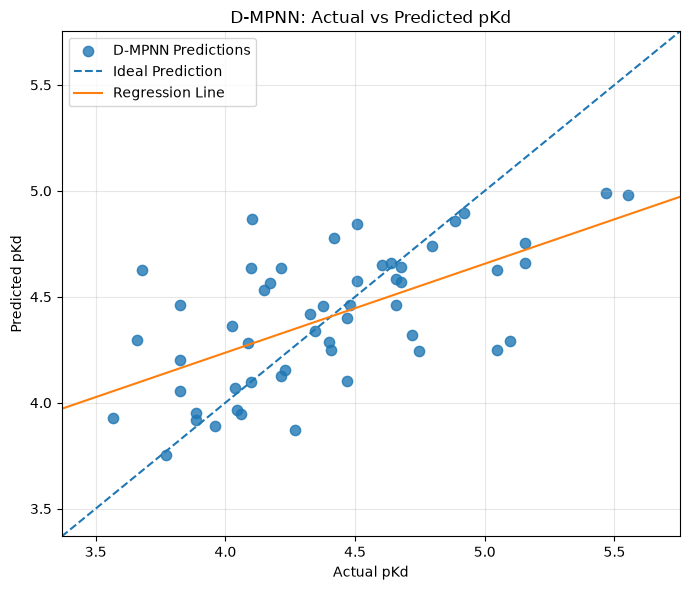

Figure saved at: /data/Zira/Chemprop_Kd_Mann/1_53/DMPNN_10Fold_Baseline/DMPNN_Actual_vs_Predicted.png


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Load out-of-fold predictions
base_dir = "/data/Zira/Chemprop_Kd_Mann/1_53"

prediction_path = os.path.join(
    base_dir,
    "DMPNN_10Fold_Baseline",
    "DMPNN_53_Compounds_OOF_Predictions.csv"
)

df_plot = pd.read_csv(prediction_path)

# Extract actual and predicted values
y_true = df_plot["Actual_pKd"]
y_pred = df_plot["Predicted_pKd"]

# Calculate regression line
slope, intercept = np.polyfit(
    y_true,
    y_pred,
    1
)

# Calculate plot limits
plot_min = min(y_true.min(), y_pred.min()) - 0.2
plot_max = max(y_true.max(), y_pred.max()) + 0.2

# Create scatter plot
plt.figure(figsize=(7, 6))

plt.scatter(
    y_true,
    y_pred,
    alpha=0.8,
    s=55,
    label="D-MPNN Predictions"
)

# Ideal prediction line
plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    linestyle="--",
    label="Ideal Prediction"
)

# Regression line
x_line = np.linspace(plot_min, plot_max, 100)

plt.plot(
    x_line,
    slope * x_line + intercept,
    label="Regression Line"
)

plt.xlabel("Actual pKd")
plt.ylabel("Predicted pKd")

plt.title("D-MPNN: Actual vs Predicted pKd")

plt.xlim(plot_min, plot_max)
plt.ylim(plot_min, plot_max)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save figure
figure_path = os.path.join(
    base_dir,
    "DMPNN_10Fold_Baseline",
    "DMPNN_Actual_vs_Predicted.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved at:", figure_path)